# Creat the database of the RFI identified 

In [5]:
# import the libraries
import h5py
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import re
import seaborn as sns



# import imageio # to collect frames and write them into an animated file.
import os
# from PIL import Image
# import io

import scienceplots
plt.style.use(['science', 'no-latex'])




#from concurrent.futures import ProcessPoolExecutor


In [6]:
def clean_instrument(name):
    """
    Clean and standardize instrument names from raw dataset entries.

    This function processes raw instrument name strings by removing metadata,
    extracting relevant identifiers, and formatting the result into a consistent,
    human-readable form. It is designed for datasets where instrument names may
    include dates, measurement configurations, and additional descriptive noise.

    Processing steps:
    -----------------
    1. Flag composite/multi-instrument entries (e.g. 'All Photogrammetry Equipment')
    2. Remove date patterns early, before any extraction (e.g., '2025_03_06', '27_06_2024')
    3. Extract instrument name from patterns like:
       '...Data<instrument_name>_<frequency>kHz'
    4. Remove unwanted keywords related to system configuration or operation
       (e.g., 'LNA', 'NoPreAmp', 'Idle', 'Radio', 'On', 'MAX')
    5. Normalize separators by collapsing multiple underscores and trimming edges
    6. Split into components and retain meaningful parts:
       - Parts containing digits (e.g., IDs, model numbers)
       - Words longer than 2 characters
    7. Format output:
       - Capitalize text components
       - Preserve alphanumeric identifiers unchanged

    Parameters
    ----------
    name : str or NaN
        Raw instrument name string from the dataset.

    Returns
    -------
    str or NaN
        Cleaned and formatted instrument name. Returns NaN if input is NaN.
        Returns a standardised composite label for multi-instrument entries.

    Examples
    --------
    >>> clean_instrument('2025_03_06_CETC_Headlight_ADLight')
    'CETC Headlight ADLight'

    >>> clean_instrument('Outliers_Clean_DataTOYOTA_HILUX_CAA286-070_100kHz_EIRP')
    'Toyota Hilux CAA286-070'

    >>> clean_instrument('Outliers_Clean_DataCETC_Hilux_CAA567-125_100kHz_EIRP_trunked')
    'CETC Hilux CAA567-125'

    >>> clean_instrument('Outliers_Clean_Data27_06_2024_CETC_Photogammetry_Light_100kHz_EIRP')
    'CETC Photogammetry Light'

    >>> clean_instrument('Outliers_Clean_Data2024_09_03_Thermometer_LNA_NoPreAmp_100kHz_EIRP')
    'Thermometer'

    >>> clean_instrument('Kiricom_Radio_On_MAX')
    'Kiricom'

    >>> clean_instrument('Outliers_Clean_DataAll_Photogrammetry_Equipment_MAX_100kHz_EIRP')
    'COMPOSITE: All Photogrammetry Equipment'

    Notes
    -----
    This function is tailored for RFI (Radio Frequency Interference) analysis workflows,
    where consistent instrument naming is critical for grouping, counting, and
    statistical interpretation.
    """

    if pd.isna(name):
        return np.nan

    name = str(name)

    # 1. Flag composite multi-instrument entries
    composite_patterns = [
        (r'All_Photogrammetry_Equipment',        'COMPOSITE: All Photogrammetry Equipment'),
        (r'Almost_All_Photogrammetry_equipment', 'COMPOSITE: Almost All Photogrammetry Equipment'),
    ]
    for pattern, label in composite_patterns:
        if re.search(pattern, name, re.IGNORECASE):
            return label

    # 2. Extract instrument name between "Data" and frequency unit — FIRST
    match = re.search(r'Data(.*?)_\d{1,5}(?:Hz|kHz|MHz|GHz)', name, re.IGNORECASE)
    if match:
        name = match.group(1)
    else:
        # No Data...kHz pattern — strip known prefixes manually
        name = re.sub(r'^Outliers_Clean_Data', '', name, flags=re.IGNORECASE)

    # 3. Remove date patterns NOW (after extraction, dates are at the front)
    name = re.sub(r'^\d{1,2}_\d{2}_\d{4}_?', '', name)   # DD_MM_YYYY at start
    name = re.sub(r'^\d{4}_\d{2}_\d{2}_?', '', name)     # YYYY_MM_DD at start
    name = re.sub(r'^\d{2}_\d{2}_\d{4}_?', '', name)     # MM_DD_YYYY at start (safety)

    # 4. Remove standalone leftover year/day tokens at start
    name = re.sub(r'^(27|2020|2024|2025)_?', '', name)

    # 5. Remove trailing fragments like Eirp, trunked
    name = re.sub(r'\b(Eirp|trunked)\b', '', name, flags=re.IGNORECASE)

    # 6. Remove unwanted configuration keywords
    unwanted = r'\b(LNA|NoPreAmp|Idle|Radio|On|MAX|Clean|Outliers|withLNA|trunked)\b'
    name = re.sub(unwanted, '', name, flags=re.IGNORECASE)

    # 7. Remove any residual frequency+unit fragments (e.g. _100kHz, _2400MHz)
    name = re.sub(r'_?\d{1,5}(?:Hz|kHz|MHz|GHz)', '', name, flags=re.IGNORECASE)

    # 8. Normalize separators
    name = re.sub(r'_+', '_', name).strip('_')

    # 9. Split and filter meaningful parts
    parts = name.split('_')
    cleaned_parts = []
    for p in parts:
        if not p:
            continue
        p = re.sub(r'(?:Hz|kHz|MHz|GHz)$', '', p, flags=re.IGNORECASE)
        if not p:
            continue
        if any(char.isdigit() for char in p) or len(p) > 2:
            cleaned_parts.append(p)

    # 10. Format: capitalize pure-text parts, preserve alphanumeric IDs as-is
    formatted = [
        p if any(char.isdigit() for char in p) else p.capitalize()
        for p in cleaned_parts
    ]

    # 11. Remove trailing standalone number (e.g. '...CAA286-070 100')
    return re.sub(r'\s+\d+$', '', ' '.join(formatted)).strip()

# Read the low and high level RFI detaset

# Load the data

Define parameters here so the notebook can easily be reused with other datasets.
low_level_RFI_peaks_EDD_2023-08-07T15_07_54.csv

EDD_2023-03-11T14_58_01

EDD_2023-04-18T18_40_20

EDD_2023-07-14T07_22_49

EDD_2023-08-07T15_07_54


In [7]:
filename = "EDD_2023-08-07T15_07_54.csv"

low_level_file = f"low_level_RFI_peaks_{filename}"
high_level_file = f"High_level_RFI_peaks_{filename}"
path = '/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/High_low_RFI_data'

In [8]:
# read the CSV files into pandas DataFrames
low_level_df = pd.read_csv(os.path.join(path, low_level_file))
high_level_df = pd.read_csv(os.path.join(path, high_level_file))

low_level_df.head()

,Time_UTC,Frequency_GHz,Power_dB,Threshold
0,2023-08-07 15:08:09,2.170343,2.189346,0.930582
1,2023-08-07 15:08:09,2.184549,1.494965,0.930582
2,2023-08-07 15:08:09,2.240759,0.934662,0.930582
3,2023-08-07 15:08:09,2.255980,0.954819,0.930582
4,2023-08-07 15:08:24,1.799520,1.033935,0.922586


In [9]:
high_level_df.head()

,Time_UTC,Frequency_GHz,Power_dB,Threshold
0,2023-08-07 15:08:09,1.819735,8.688568,1.300742
1,2023-08-07 15:08:09,2.002890,13.147339,1.300742
2,2023-08-07 15:08:09,2.170343,2.189346,1.300742
3,2023-08-07 15:08:09,2.184149,1.816361,1.300742
4,2023-08-07 15:08:09,2.200064,11.060791,1.300742


In [10]:
# read the photogametric data
path = '/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/High_low_RFI_data'
photogametric_data = pd.read_csv(f'{path}/all_instruments_master_outlier.csv')

photogametric_data['Instrument_clean'] = photogametric_data['Instrument'].apply(clean_instrument)
photogametric_data['Instrument_clean'].unique()

photogametric_data

,Instrument,Frequency,Amplitude,Methods,Instrument_clean
0,Outliers_Clean_DataTOYOTA_HILUX_CAA286-070_100...,126.909091,-96.302726,"Std-Dev, IQR",Toyota Hilux CAA286-070
1,Outliers_Clean_DataTOYOTA_HILUX_CAA286-070_100...,152.363637,-97.612557,"Std-Dev, IQR",Toyota Hilux CAA286-070
2,Outliers_Clean_DataTOYOTA_HILUX_CAA286-070_100...,343.636364,-94.981217,"Std-Dev, IQR",Toyota Hilux CAA286-070
3,Outliers_Clean_DataTOYOTA_HILUX_CAA286-070_100...,454.909091,-107.066533,"Std-Dev, IQR, Modified-Z",Toyota Hilux CAA286-070
4,Outliers_Clean_DataTOYOTA_HILUX_CAA286-070_100...,553.636364,-94.559155,"Std-Dev, IQR",Toyota Hilux CAA286-070
...,...,...,...,...,...
8903,Outliers_Clean_DataAll_Photogrammetry_Equipmen...,5290.895000,-55.439650,IQR,COMPOSITE: All Photogrammetry Equipment
8904,Outliers_Clean_DataAll_Photogrammetry_Equipmen...,5593.740000,-55.602671,IQR,COMPOSITE: All Photogrammetry Equipment
8905,Outliers_Clean_DataAll_Photogrammetry_Equipmen...,5711.215000,-55.605755,IQR,COMPOSITE: All Photogrammetry Equipment
8906,Outliers_Clean_DataAll_Photogrammetry_Equipmen...,5931.457500,-103.670339,IQR,COMPOSITE: All Photogrammetry Equipment


In [11]:
photogametric_data['Instrument'].unique()


<StringArray>
[                        'Outliers_Clean_DataTOYOTA_HILUX_CAA286-070_100kHz_EIRP_trunked',
                                 'Outliers_Clean_Datamesswelk_CLINO2000_L4563_10kHz_EIRP',
                           'Outliers_Clean_DataCETC_Hilux_CAA567-125_100kHz_EIRP_trunked',
                                  'Outliers_Clean_DataTEREX_60T_Crane_100Hz_EIRP_trunked',
                                    'Outliers_Clean_DataKiricom_Radio_On_MAX_100kHz_EIRP',
                     'Outliers_Clean_Data27_06_2024_CETC_Photogammetry_Light_100kHz_EIRP',
                     'Outliers_Clean_Data2024_09_03_Thermometer_LNA_NoPreAmp_100kHz_EIRP',
                    'Outliers_Clean_Data2025_03_06_CETC_Headlight_ADLight_1kHz_1kHz_EIRP',
                                  'Outliers_Clean_DataJLG4017-500630_100kHz_EIRP_trunked',
                    'Outliers_Clean_Data2025_03_19_CETC_Photogammetry_Camera_100kHz_EIRP',
                 'Outliers_Clean_Data2025_03_20_CETC_Lenovo_T14_Idle_withLNA

In [12]:
hilux = photogametric_data[photogametric_data['Instrument'].str.contains('27 06', case=False, na=False)]
hilux

,Instrument,Frequency,Amplitude,Methods,Instrument_clean


In [13]:
photogametric_data['Instrument_clean'].unique()

<StringArray>
[                     'Toyota Hilux CAA286-070',
                     'Messwelk CLINO2000 L4563',
                        'Cetc Hilux CAA567-125',
                              'Terex 60T Crane',
                            'Kiricom Radio Max',
                     'Cetc Photogammetry Light',
                     'Thermometer Lna Nopreamp',
                       'Cetc Headlight Adlight',
                               'JLG4017-500630',
                    'Cetc Photogammetry Camera',
                 'Cetc Lenovo T14 Idle Withlna',
                                  'Inca Camera',
 'Cetc Photogrammetry Camera DH1200 And Laptop',
                            'Cetc Nikon Camera',
      'COMPOSITE: All Photogrammetry Equipment',
 'Cetc Photogrammetry Camera HR1200 And Laptop',
                       'Windmeter Lna Nopreamp',
                      'Superfire HL58 Headlamp',
                  'Zoomlion Cherrypicker ZA32J',
                    'Liebherr LTM1055-3.2 TC16',
      

In [14]:
#converte the frequency from MHz to GHz
photogametric_data['Frequency_GHz'] = photogametric_data['Frequency'] / 1000  # Convert MHz to GHz

photogametric_data.head()

,Instrument,Frequency,Amplitude,Methods,Instrument_clean,Frequency_GHz
0,Outliers_Clean_DataTOYOTA_HILUX_CAA286-070_100...,126.909091,-96.302726,"Std-Dev, IQR",Toyota Hilux CAA286-070,0.126909
1,Outliers_Clean_DataTOYOTA_HILUX_CAA286-070_100...,152.363637,-97.612557,"Std-Dev, IQR",Toyota Hilux CAA286-070,0.152364
2,Outliers_Clean_DataTOYOTA_HILUX_CAA286-070_100...,343.636364,-94.981217,"Std-Dev, IQR",Toyota Hilux CAA286-070,0.343636
3,Outliers_Clean_DataTOYOTA_HILUX_CAA286-070_100...,454.909091,-107.066533,"Std-Dev, IQR, Modified-Z",Toyota Hilux CAA286-070,0.454909
4,Outliers_Clean_DataTOYOTA_HILUX_CAA286-070_100...,553.636364,-94.559155,"Std-Dev, IQR",Toyota Hilux CAA286-070,0.553636


# Search for harmonic frequency

In [15]:


# Frequency tolerance (GHz)
# Example: 1 MHz = 0.001 GHz
tolerance = 0.001


# Maximum harmonic to search
max_harmonic = 10


harmonic_matches = []


for _, inst in photogametric_data.iterrows():

    inst_freq = inst["Frequency_GHz"]

    for n in range(2, max_harmonic + 1):

        harmonic_freq = inst_freq * n


        # Find RFI close to harmonic frequency
        matches = high_level_df[
            np.abs(high_level_df["Frequency_GHz"] - harmonic_freq) <= tolerance
        ]


        for _, rfi in matches.iterrows():

            harmonic_matches.append({

                "Instrument": inst["Instrument_clean"],
                "Instrument_Frequency_GHz": inst_freq,

                "Harmonic_Order": n,
                "Harmonic_Frequency_GHz": harmonic_freq,

                "Detected_Time": rfi["Time_UTC"],
                "Detected_Frequency_GHz": rfi["Frequency_GHz"],

                "Power_dB": rfi["Power_dB"],
                "Threshold": rfi["Threshold"],

                "Frequency_Difference_GHz":
                    abs(rfi["Frequency_GHz"] - harmonic_freq)
            })


# Create dataframe
harmonic_df = pd.DataFrame(harmonic_matches)


# Save result
harmonic_df.to_csv(
    "instrument_harmonic_matches.csv",
    index=False
)


harmonic_df

,Instrument,Instrument_Frequency_GHz,Harmonic_Order,Harmonic_Frequency_GHz,Detected_Time,Detected_Frequency_GHz,Power_dB,Threshold,Frequency_Difference_GHz
0,Toyota Hilux CAA286-070,0.454909,4,1.819636,2023-08-07 15:08:09,1.819735,8.688568,1.300742,0.000098
1,Toyota Hilux CAA286-070,0.454909,4,1.819636,2023-08-07 15:08:24,1.819735,8.821716,1.304311,0.000098
2,Toyota Hilux CAA286-070,0.454909,4,1.819636,2023-08-07 15:08:39,1.819735,8.824554,1.299768,0.000098
3,Toyota Hilux CAA286-070,0.454909,4,1.819636,2023-08-07 15:08:54,1.819735,8.658569,1.283736,0.000098
4,Toyota Hilux CAA286-070,0.454909,4,1.819636,2023-08-07 15:09:09,1.819735,8.612534,1.295991,0.000098
...,...,...,...,...,...,...,...,...,...
673,COMPOSITE: All Photogrammetry Equipment,0.667396,3,2.002187,2023-08-07 15:08:39,2.002943,12.938034,1.299768,0.000756
674,COMPOSITE: All Photogrammetry Equipment,0.667396,3,2.002187,2023-08-07 15:08:54,2.002890,12.964966,1.283736,0.000703
675,COMPOSITE: All Photogrammetry Equipment,0.667396,3,2.002187,2023-08-07 15:09:09,2.002916,13.181946,1.295991,0.000730
676,COMPOSITE: All Photogrammetry Equipment,0.667396,3,2.002187,2023-08-07 15:09:24,2.002943,13.186600,1.304297,0.000756


In [23]:
harmonic_df['Harmonic_Order'].unique()

array([ 4,  7,  8,  3,  6,  2, 10,  9,  5])

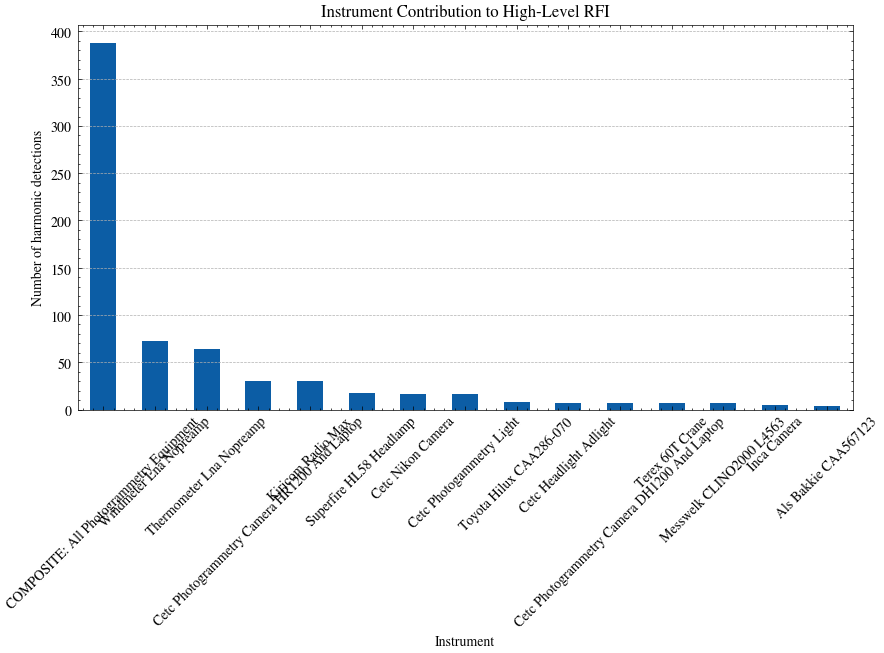

In [17]:

instrument_counts = (
    harmonic_df
    .groupby("Instrument")
    .size()
    .sort_values(ascending=False)
)


plt.figure(figsize=(10,5))

instrument_counts.plot(
    kind="bar"
)

plt.xlabel("Instrument")
plt.ylabel("Number of harmonic detections")

plt.title("Instrument Contribution to High-Level RFI")

plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--")

plt.show()

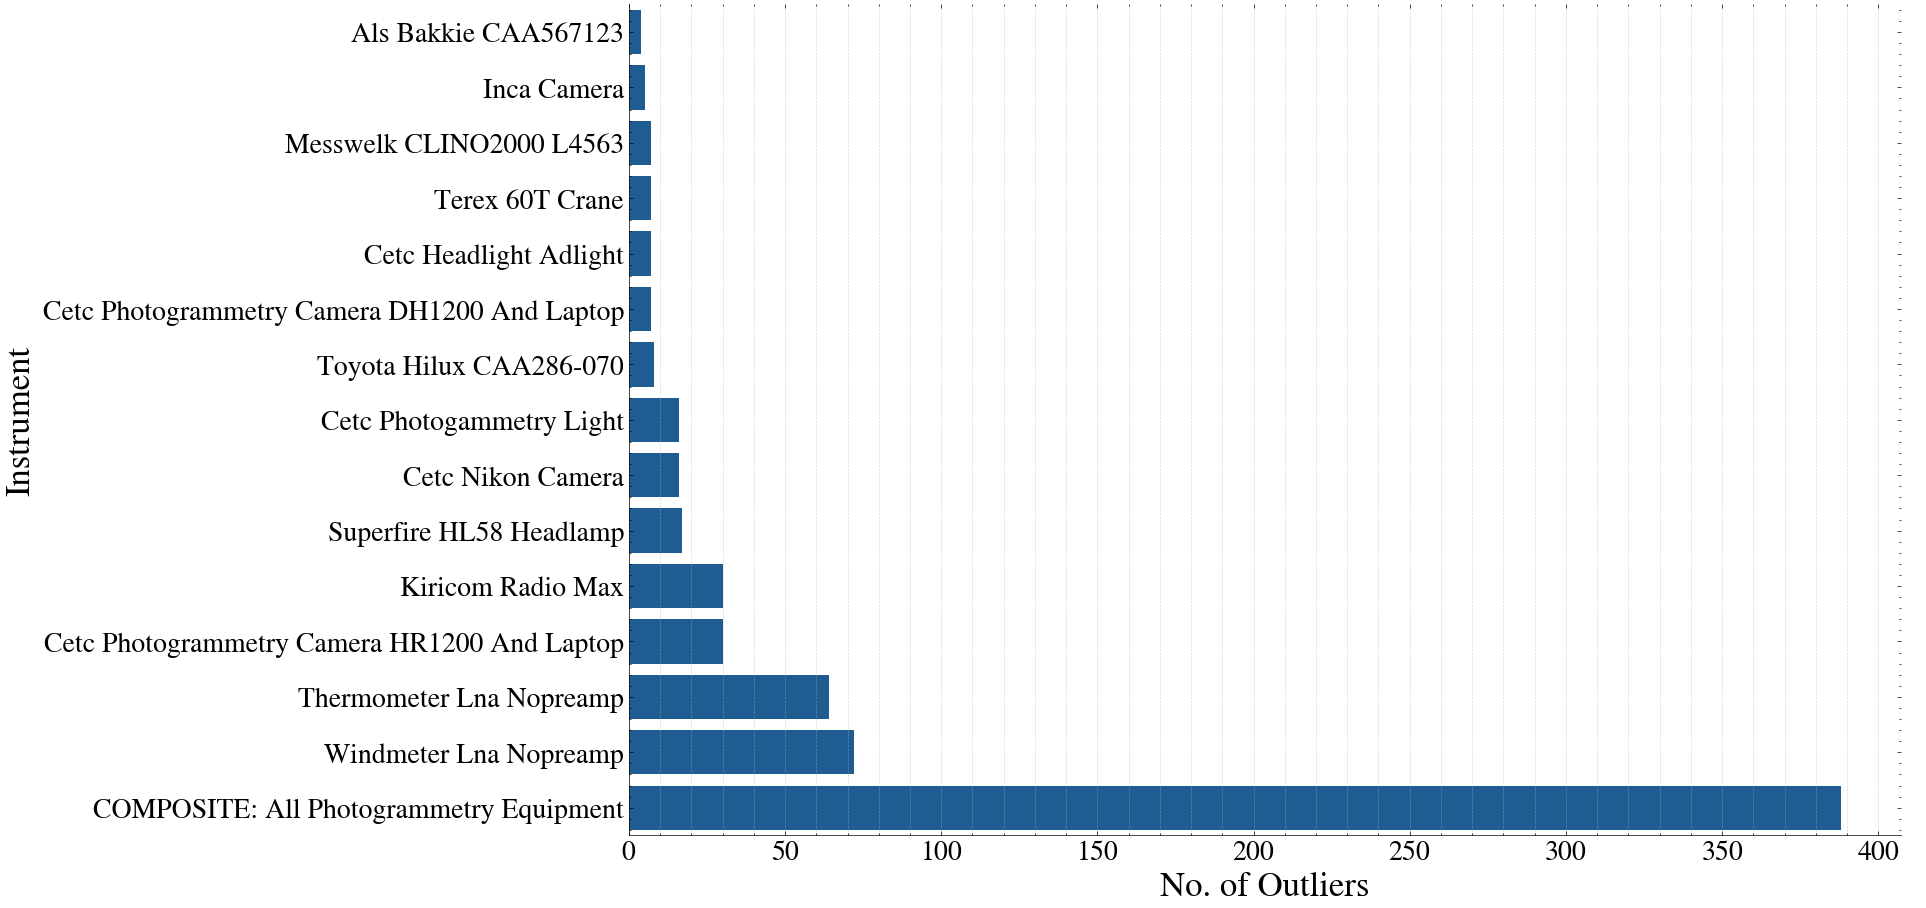

In [25]:
g = sns.catplot(
    data=harmonic_df,
    kind='count',
    y="Instrument",
    order=harmonic_df['Instrument'].value_counts(ascending=True).index,
    height=9,
    aspect=1.8
)

# Axis labels (bigger)
g.set_axis_labels("No. of Outliers", "Instrument")

# Increase font sizes
for ax in g.axes.flat:
    ax.set_xlabel("No. of Outliers", fontsize=25)
    ax.set_ylabel("Instrument", fontsize=25)
    ax.grid(True, which='both', axis='x', linestyle='--', alpha=0.5)

    # Tick labels
    ax.tick_params(axis='both', labelsize=20)

# plt.savefig("/home/garces/Desktop/Master/Data/All_EIRP_Files/Outlier_Detection/instrument_count_plot.png", dpi=300, bbox_inches='tight')
# plt.show()

In [ ]:

# Frequency tolerance (GHz)
# Example: 1 MHz = 0.001 GHz
tolerance = 0.001


# Maximum harmonic to search
max_harmonic = 10


harmonic_matches_low = []


for _, inst in photogametric_data.iterrows():

    inst_freq = inst["Frequency_GHz"]

    for n in range(2, max_harmonic + 1):

        harmonic_freq = inst_freq * n


        # Find RFI close to harmonic frequency
        matches = low_level_df[
            np.abs(low_level_df["Frequency_GHz"] - harmonic_freq) <= tolerance
        ]


        for _, rfi in matches.iterrows():

            harmonic_matches_low.append({

                "Instrument": inst["Instrument"],
                "Instrument_Frequency_GHz": inst_freq,

                "Harmonic_Order": n,
                "Harmonic_Frequency_GHz": harmonic_freq,

                "Detected_Time": rfi["Time_UTC"],
                "Detected_Frequency_GHz": rfi["Frequency_GHz"],

                "Power_dB": rfi["Power_dB"],
                "Threshold": rfi["Threshold"],

                "Frequency_Difference_GHz":
                    abs(rfi["Frequency_GHz"] - harmonic_freq)
            })


# Create dataframe
harmonic_df_low = pd.DataFrame(harmonic_matches_low)


# Save result
harmonic_df_low.to_csv(
    "instrument_harmonic_matches.csv",
    index=False
)


harmonic_df_low

,Instrument,Instrument_Frequency_GHz,Harmonic_Order,Harmonic_Frequency_GHz,Detected_Time,Detected_Frequency_GHz,Power_dB,Threshold,Frequency_Difference_GHz
0,Outliers_Clean_DataTOYOTA_HILUX_CAA286-070_100...,0.374909,7,2.624364,2023-08-07 15:08:24,2.624987,1.122360,0.922586,0.000623
1,Outliers_Clean_DataTOYOTA_HILUX_CAA286-070_100...,0.374909,7,2.624364,2023-08-07 15:08:54,2.624987,1.689957,0.919497,0.000623
2,Outliers_Clean_DataTOYOTA_HILUX_CAA286-070_100...,0.374909,7,2.624364,2023-08-07 15:09:39,2.624987,1.282562,0.922965,0.000623
3,Outliers_Clean_DataTOYOTA_HILUX_CAA286-070_100...,0.543636,4,2.174545,2023-08-07 15:09:09,2.174109,1.069031,0.919902,0.000437
4,Outliers_Clean_DataTOYOTA_HILUX_CAA286-070_100...,1.120000,2,2.240000,2023-08-07 15:08:09,2.240759,0.934662,0.930582,0.000759
...,...,...,...,...,...,...,...,...,...
436,Outliers_Clean_DataAll_Photogrammetry_Equipmen...,0.921750,2,1.843500,2023-08-07 15:08:39,1.843206,0.949707,0.915259,0.000294
437,Outliers_Clean_DataAll_Photogrammetry_Equipmen...,0.921793,2,1.843587,2023-08-07 15:08:39,1.843206,0.949707,0.915259,0.000380
438,Outliers_Clean_DataAll_Photogrammetry_Equipmen...,1.086307,2,2.172615,2023-08-07 15:09:39,2.172346,1.044006,0.922965,0.000269
439,Outliers_Clean_DataAll_Photogrammetry_Equipmen...,1.086497,2,2.172994,2023-08-07 15:09:39,2.172346,1.044006,0.922965,0.000648


In [ ]:
# filter the second order harmonics
harmonic_df_low = harmonic_df_low[harmonic_df_low["Harmonic_Order"] == 2]
harmonic_df_low

,Instrument,Instrument_Frequency_GHz,Harmonic_Order,Harmonic_Frequency_GHz,Detected_Time,Detected_Frequency_GHz,Power_dB,Threshold,Frequency_Difference_GHz
4,Outliers_Clean_DataTOYOTA_HILUX_CAA286-070_100...,1.120000,2,2.240000,2023-08-07 15:08:09,2.240759,0.934662,0.930582,0.000759
28,Outliers_Clean_DataKiricom_Radio_On_MAX_100kHz...,1.188890,2,2.377780,2023-08-07 15:09:39,2.377745,0.941086,0.922965,0.000035
79,Outliers_Clean_Data2025_03_19_CETC_Photogammet...,0.899735,2,1.799470,2023-08-07 15:08:24,1.799520,1.033935,0.922586,0.000050
80,Outliers_Clean_Data2025_03_19_CETC_Photogammet...,1.637423,2,3.274845,2023-08-07 15:09:09,3.275415,1.026398,0.919902,0.000570
81,Outliers_Clean_Data2025_03_20_CETC_Lenovo_T14_...,1.120532,2,2.241065,2023-08-07 15:08:09,2.240759,0.934662,0.930582,0.000306
...,...,...,...,...,...,...,...,...,...
436,Outliers_Clean_DataAll_Photogrammetry_Equipmen...,0.921750,2,1.843500,2023-08-07 15:08:39,1.843206,0.949707,0.915259,0.000294
437,Outliers_Clean_DataAll_Photogrammetry_Equipmen...,0.921793,2,1.843587,2023-08-07 15:08:39,1.843206,0.949707,0.915259,0.000380
438,Outliers_Clean_DataAll_Photogrammetry_Equipmen...,1.086307,2,2.172615,2023-08-07 15:09:39,2.172346,1.044006,0.922965,0.000269
439,Outliers_Clean_DataAll_Photogrammetry_Equipmen...,1.086497,2,2.172994,2023-08-07 15:09:39,2.172346,1.044006,0.922965,0.000648
